IMPORT LIBRARY

Analisis: Data sensor dibuat dalam rentang simulasi. Skor digunakan untuk menetapkan label kesegaran sehingga model mempunyai target untuk dipelajari. Aturan ini hanya asumsi, bukan standar ilmiah penentuan kesegaran daging.

Analisis: Dataset terdiri dari tiga kolom fitur dan satu kolom target. Pemeriksaan awal dilakukan untuk melihat struktur data dan jumlah sampel pada setiap kelas.

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

print("Library berhasil diimpor")




Library berhasil diimpor


Analisis: Library digunakan untuk mengolah data, membangun model Random Forest, mengevaluasi hasil klasifikasi, membuat visualisasi, dan menyimpan model.

MEMBUAT DATASET SIMULASI

In [9]:
# 1. Menentukan jumlah data simulasi
np.random.seed(42)
n_samples = 1000

# 2. Membuat data sensor simulasi
gas_sensor = np.random.uniform(100, 900, n_samples)
suhu = np.random.uniform(22.0, 35.0, n_samples)
kelembapan = np.random.uniform(40.0, 90.0, n_samples)

# 3. Menghitung skor simulasi penurunan kesegaran
skor = (
    0.5 * ((gas_sensor - 100) / 800) +
    0.3 * ((suhu - 22) / 13) +
    0.2 * ((kelembapan - 40) / 50)
)

# 4. Menentukan kelas kesegaran
kesegaran = np.where(
    skor < 0.33,
    "Segar",
    np.where(skor < 0.66, "Cukup Segar", "Tidak Segar")
)

print("Dataset simulasi berhasil dibuat")
print("Jumlah sampel:", n_samples)


Dataset simulasi berhasil dibuat
Jumlah sampel: 1000


Membentuk dan melihat dataset

In [7]:

import numpy as np
import pandas as pd

# 1. Data uji coba: [Suhu, Kelembapan, MQ135]
data_uji_coba = np.array([
    [24.0, 55.0, 120],
    [29.5, 76.0, 450],
    [33.0, 85.0, 810]
])

# 2. Normalisasi menggunakan scaler yang sama
data_uji_scaled = scaler.transform(data_uji_coba)

# 3. Melakukan prediksi
prediksi_hasil = knn_model.predict(data_uji_scaled)

# 4. Menampilkan hasil prediksi
hasil_prediksi = pd.DataFrame(
    data_uji_coba,
    columns=["Suhu", "Kelembapan", "MQ135"]
)

hasil_prediksi["Prediksi Kondisi"] = prediksi_hasil

print("--- HASIL UJI COBA PREDIKSI KESEGARAN DAGING ---")
display(hasil_prediksi)


--- HASIL UJI COBA PREDIKSI KESEGARAN DAGING ---


C:\Users\NATASYA\miniconda3\envs\dataku\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


,Suhu,Kelembapan,MQ135,Prediksi Kondisi
0,24.0,55.0,120.0,Segar
1,29.5,76.0,450.0,Mulai Membusuk
2,33.0,85.0,810.0,Busuk


In [10]:
data = pd.DataFrame({
    "gas_sensor": gas_sensor,
    "suhu": suhu,
    "kelembapan": kelembapan,
    "kesegaran": kesegaran
})

print("Lima data pertama:")
display(data.head())

print("\nInformasi dataset:")
print(data.info())

print("\nJumlah setiap kelas:")
print(data["kesegaran"].value_counts())

Lima data pertama:


,gas_sensor,suhu,kelembapan,kesegaran
0,399.632095,24.406728,53.085284,Segar
1,860.571445,29.044712,52.348940,Tidak Segar
2,685.595153,33.348296,85.312729,Tidak Segar
3,578.926787,31.518924,52.477310,Cukup Segar
4,224.814912,32.485295,53.597486,Cukup Segar



Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   gas_sensor  1000 non-null   float64
 1   suhu        1000 non-null   float64
 2   kelembapan  1000 non-null   float64
 3   kesegaran   1000 non-null   str    
dtypes: float64(3), str(1)
memory usage: 31.4 KB
None

Jumlah setiap kelas:
kesegaran
Cukup Segar    584
Segar          212
Tidak Segar    204
Name: count, dtype: int64


In [11]:
# Fitur yang digunakan sebagai input
X = data[["gas_sensor", "suhu", "kelembapan"]]

# Target yang akan diprediksi
y = data["kesegaran"]

print("Jumlah fitur:", X.shape[1])
print("Jumlah data:", X.shape[0])
print("Kelas target:", y.unique())

Jumlah fitur: 3
Jumlah data: 1000
Kelas target: <StringArray>
['Segar', 'Tidak Segar', 'Cukup Segar']
Length: 3, dtype: str


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Jumlah data latih:", len(X_train))
print("Jumlah data uji:", len(X_test))

Jumlah data latih: 800
Jumlah data uji: 200


In [13]:
# Membuat model Random Forest
model = RandomForestClassifier(
    n_estimators=100,
    max_depth=None,
    random_state=42
)

# Melatih model
model.fit(X_train, y_train)

print("Model Random Forest berhasil dilatih")

Model Random Forest berhasil dilatih


In [14]:
# Prediksi data uji
y_pred = model.predict(X_test)

# Menampilkan beberapa hasil prediksi
hasil = pd.DataFrame({
    "Aktual": y_test.values,
    "Prediksi": y_pred
})

display(hasil.head(10))

,Aktual,Prediksi
0,Tidak Segar,Cukup Segar
1,Cukup Segar,Tidak Segar
2,Tidak Segar,Tidak Segar
3,Cukup Segar,Cukup Segar
4,Tidak Segar,Tidak Segar
5,Cukup Segar,Cukup Segar
6,Cukup Segar,Cukup Segar
7,Segar,Segar
8,Tidak Segar,Tidak Segar
9,Cukup Segar,Cukup Segar


In [15]:
# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Random Forest:",
      round(akurasi * 100, 2), "%")

# Menampilkan precision, recall, dan F1-score
print("\nLaporan Klasifikasi:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Segar", "Cukup Segar", "Tidak Segar"],
    zero_division=0
))

Akurasi Random Forest: 91.5 %

Laporan Klasifikasi:
              precision    recall  f1-score   support

       Segar       0.97      0.83      0.90        42
 Cukup Segar       0.90      0.96      0.93       117
 Tidak Segar       0.90      0.88      0.89        41

    accuracy                           0.92       200
   macro avg       0.93      0.89      0.91       200
weighted avg       0.92      0.92      0.91       200



In [16]:
# Menghitung akurasi
akurasi = accuracy_score(y_test, y_pred)

print("Akurasi Random Forest:",
      round(akurasi * 100, 2), "%")

# Menampilkan precision, recall, dan F1-score
print("\nLaporan Klasifikasi:")
print(classification_report(
    y_test,
    y_pred,
    labels=["Segar", "Cukup Segar", "Tidak Segar"],
    zero_division=0
))

Akurasi Random Forest: 91.5 %

Laporan Klasifikasi:
              precision    recall  f1-score   support

       Segar       0.97      0.83      0.90        42
 Cukup Segar       0.90      0.96      0.93       117
 Tidak Segar       0.90      0.88      0.89        41

    accuracy                           0.92       200
   macro avg       0.93      0.89      0.91       200
weighted avg       0.92      0.92      0.91       200



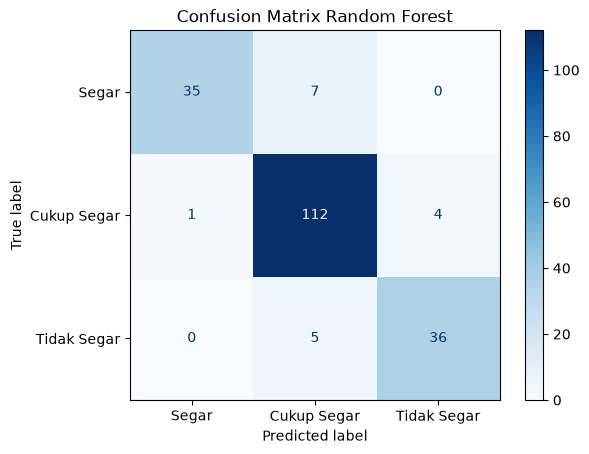

In [17]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Segar", "Cukup Segar", "Tidak Segar"]
)

tampilan = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Segar", "Cukup Segar", "Tidak Segar"]
)

tampilan.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix Random Forest")
plt.show()

        Fitur  Importance
0  gas_sensor    0.545298
1        suhu    0.263238
2  kelembapan    0.191464


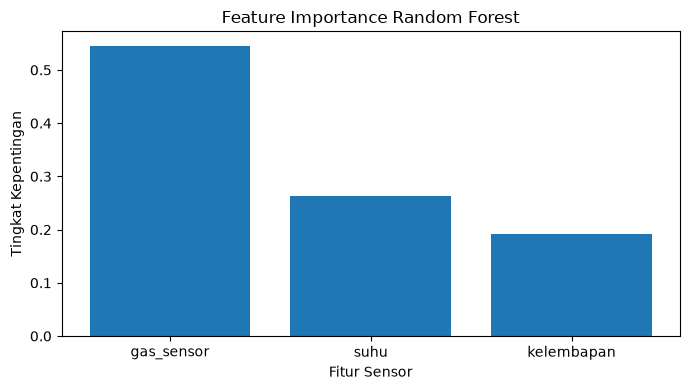

In [18]:
importance = pd.DataFrame({
    "Fitur": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

plt.figure(figsize=(7, 4))
plt.bar(importance["Fitur"], importance["Importance"])
plt.title("Feature Importance Random Forest")
plt.xlabel("Fitur Sensor")
plt.ylabel("Tingkat Kepentingan")
plt.tight_layout()
plt.show()

In [19]:
# Data sensor baru
data_baru = pd.DataFrame({
    "gas_sensor": [250],
    "suhu": [25.0],
    "kelembapan": [60.0]
})

# Prediksi kelas
prediksi = model.predict(data_baru)

print("Gas sensor :", data_baru["gas_sensor"].iloc[0])
print("Suhu       :", data_baru["suhu"].iloc[0], "°C")
print("Kelembapan :", data_baru["kelembapan"].iloc[0], "%")
print("Hasil klasifikasi:", prediksi[0])

Gas sensor : 250
Suhu       : 25.0 °C
Kelembapan : 60.0 %
Hasil klasifikasi: Segar


In [20]:
joblib.dump(model, "model_kesegaran_daging.joblib")

print("Model berhasil disimpan")

Model berhasil disimpan
